# 06 Final Evaluation

Evaluate the three toxicity classification approaches on the held-out test set:

- Rule-Based Detector
- TF-IDF + Logistic Regression
- Context-Aware MLP

The test set is used only for final evaluation and is not used for model tuning.

## 1. Load Dataset and Fixed Split

读取最终标注数据和固定的数据划分，建立最终 test set。

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "labeled_context_1200.parquet"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dataset_split.parquet"
)

df = pd.read_parquet(DATA_PATH)
split_data = pd.read_parquet(SPLIT_PATH)

df = df.merge(
    split_data[
        [
            "annotation_id",
            "split"
        ]
    ],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

print("Dataset:")
print(df.shape)

print("\nSplit distribution:")
print(
    df["split"].value_counts()
)

Dataset:
(1200, 27)

Split distribution:
split
train         838
validation    183
test          179
Name: count, dtype: int64


## 2. Create Final Test Set

提取之前保留的 test set，用于最终模型比较。

In [2]:
test_df = (
    df[
        df["split"] == "test"
    ]
    .copy()
)

test_df["key"] = (
    test_df["key"]
    .fillna("")
    .astype(str)
)

y_test = (
    test_df["label"]
    .astype(int)
    .to_numpy()
)

print("Test rows:")
print(len(test_df))

print("\nTest label distribution:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

Test rows:
179

Test label distribution:
label
0    56
1    73
2    50
Name: count, dtype: int64


## 3. Load Text-Only Baseline

读取在 `04_baseline_models.ipynb` 中训练并保存的 TF-IDF 和 Logistic Regression 模型。

In [3]:
import joblib

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

baseline_tfidf = joblib.load(
    MODEL_DIR
    / "baseline_tfidf.joblib"
)

baseline_logistic = joblib.load(
    MODEL_DIR
    / "baseline_logistic.joblib"
)

X_test_tfidf = (
    baseline_tfidf.transform(
        test_df["key"]
    )
)

logistic_test_predictions = (
    baseline_logistic.predict(
        X_test_tfidf
    )
)

print("TF-IDF test shape:")
print(X_test_tfidf.shape)

print("\nLogistic predictions:")
print(len(logistic_test_predictions))

TF-IDF test shape:
(179, 397)

Logistic predictions:
179


## 4. Apply Rule-Based Detector

使用与 baseline notebook 相同的敏感词规则，对最终 test set 进行预测。

In [4]:
import re

harmful_patterns = [
    r"\bfuck you\b",
    r"\bfuck u\b",
    r"\bkys\b",
    r"\bkill yourself\b",
    r"\bretard\b",
    r"\bretarded\b",
    r"\bidiot\b",
    r"\bstupid\b",
    r"\btrash\b",
    r"\bnoob\b",
    r"\bcunt\b",
    r"\bfaggot\b",
    r"\bnigger\b",
    r"\bnigga\b",
    r"\buninstall\b"
]

emotional_patterns = [
    r"\bwtf\b",
    r"\bfuck\b",
    r"\bshit\b",
    r"\bdamn\b",
    r"\bsad\b",
    r"\bbad\b",
    r"\blost\b",
    r"\blose\b",
    r"\bthrow\b",
    r"\bthrowing\b",
    r"\breport\b",
    r"\bez\b",
    r"\beasy\b"
]


def sensitive_word_detector(message):
    text = str(message).lower()

    for pattern in harmful_patterns:
        if re.search(pattern, text):
            return 2

    for pattern in emotional_patterns:
        if re.search(pattern, text):
            return 1

    return 0


rule_test_predictions = (
    test_df["key"]
    .apply(
        sensitive_word_detector
    )
    .to_numpy()
)

print("Rule predictions:")
print(len(rule_test_predictions))

Rule predictions:
179


## 5. Load Context Model Components

读取 `05_context_model.ipynb` 保存的 TF-IDF、SVD、数值处理组件和 Context-Aware MLP。

In [5]:
current_tfidf = joblib.load(
    MODEL_DIR / "context_current_tfidf.joblib"
)

current_svd = joblib.load(
    MODEL_DIR / "context_current_svd.joblib"
)

history_tfidf = joblib.load(
    MODEL_DIR / "context_history_tfidf.joblib"
)

history_svd = joblib.load(
    MODEL_DIR / "context_history_svd.joblib"
)

numeric_imputer = joblib.load(
    MODEL_DIR / "context_numeric_imputer.joblib"
)

numeric_scaler = joblib.load(
    MODEL_DIR / "context_numeric_scaler.joblib"
)

print("Context preprocessing components loaded.")

Context preprocessing components loaded.


## 6. Build Test Text Features

按照与 Context Model 训练时相同的方式，建立当前消息和前五条聊天历史文本。

In [7]:
history_columns = [
    "prev_message_5",
    "prev_message_4",
    "prev_message_3",
    "prev_message_2",
    "prev_message_1"
]

test_df["history_text"] = (
    test_df[history_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

test_df["current_text"] = (
    test_df["key"]
    .fillna("")
    .astype(str)
)

In [8]:
X_test_current_tfidf = (
    current_tfidf.transform(
        test_df["current_text"]
    )
)

X_test_current = (
    current_svd.transform(
        X_test_current_tfidf
    )
)

X_test_history_tfidf = (
    history_tfidf.transform(
        test_df["history_text"]
    )
)

X_test_history = (
    history_svd.transform(
        X_test_history_tfidf
    )
)

print("Current text:")
print(X_test_current.shape)

print("\nHistory text:")
print(X_test_history.shape)

Current text:
(179, 50)

History text:
(179, 50)


## 7. Build Test Context Features

使用训练阶段已经保存的缺失值处理和标准化组件，转换 test set 的结构化上下文特征。

In [9]:
numeric_features = [
    "messages_last_60s",
    "message_interval",
    "gold",
    "xp",
    "last_hits",
    "seconds_since_teamfight"
]

binary_features = [
    "repeated_message_60s",
    "recent_teamfight_120s",
    "recent_teamfight_loss_120s"
]

X_test_numeric = (
    numeric_imputer.transform(
        test_df[numeric_features]
    )
)

X_test_numeric = (
    numeric_scaler.transform(
        X_test_numeric
    )
)

X_test_binary = (
    test_df[binary_features]
    .astype(float)
    .to_numpy()
)

print("Numeric context:")
print(X_test_numeric.shape)

print("\nBinary context:")
print(X_test_binary.shape)

Numeric context:
(179, 8)

Binary context:
(179, 3)


## 8. Combine Test Features

将当前消息、聊天历史、数值上下文和二元上下文组合成 Context-Aware MLP 的最终输入。

In [10]:
X_test_context = np.hstack([
    X_test_current,
    X_test_history,
    X_test_numeric,
    X_test_binary
])

print("Context test input:")
print(X_test_context.shape)

Context test input:
(179, 111)


## 9. Load Context-Aware MLP

重新建立与训练阶段相同的 MLP 结构，并读取保存的最佳模型参数。

In [11]:
import torch
import torch.nn as nn

class ContextMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

context_model = ContextMLP(
    X_test_context.shape[1]
)

context_model.load_state_dict(
    torch.load(
        MODEL_DIR / "context_mlp.pt",
        map_location=device
    )
)

context_model = context_model.to(device)
context_model.eval()

print("Context model loaded.")

print("\nInput size:")
print(X_test_context.shape[1])

Context model loaded.

Input size:
111


## 10. Predict with Context Model

使用保存的最佳 Context-Aware MLP 对最终 test set 进行预测。

In [12]:
X_test_tensor = torch.tensor(
    X_test_context,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    context_outputs = context_model(
        X_test_tensor
    )

    context_test_predictions = (
        torch.argmax(
            context_outputs,
            dim=1
        )
        .cpu()
        .numpy()
    )

print("Context predictions:")
print(len(context_test_predictions))

Context predictions:
179


## 11. Compare Final Test Performance

在最终 test set 上比较 Rule-Based Detector、TF-IDF + Logistic Regression 和 Context-Aware MLP。

使用 Accuracy 和 Macro-F1 作为整体评价指标。

In [13]:
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

models = {
    "Rule-Based Detector": rule_test_predictions,
    "TF-IDF + Logistic Regression": logistic_test_predictions,
    "Context-Aware MLP": context_test_predictions
}

final_results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

final_results_df = pd.DataFrame(
    final_results
)

display(
    final_results_df.round(4)
)

,Model,Accuracy,Macro F1
0,Rule-Based Detector,0.8101,0.8112
1,TF-IDF + Logistic Regression,0.7821,0.7845
2,Context-Aware MLP,0.7877,0.7889


## 12. Classification Reports

查看三个模型在 Normal、Limited Emotional 和 Harmful 三个类别上的 Precision、Recall 和 F1。

In [14]:
from sklearn.metrics import classification_report

for model_name, predictions in models.items():

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "Normal",
                "Limited Emotional",
                "Harmful"
            ],
            digits=3
        )
    )

Rule-Based Detector
                   precision    recall  f1-score   support

           Normal      0.736     0.946     0.828        56
Limited Emotional      0.803     0.781     0.792        73
          Harmful      0.972     0.700     0.814        50

         accuracy                          0.810       179
        macro avg      0.837     0.809     0.811       179
     weighted avg      0.829     0.810     0.809       179

TF-IDF + Logistic Regression
                   precision    recall  f1-score   support

           Normal      0.734     0.839     0.783        56
Limited Emotional      0.794     0.740     0.766        73
          Harmful      0.830     0.780     0.804        50

         accuracy                          0.782       179
        macro avg      0.786     0.786     0.784       179
     weighted avg      0.785     0.782     0.782       179

Context-Aware MLP
                   precision    recall  f1-score   support

           Normal      0.776     0.804   

## 13. Compare Per-Class F1

比较三个模型在每个类别上的 F1 score，观察 Context 对不同类别的影响。

In [15]:
from sklearn.metrics import precision_recall_fscore_support

class_names = [
    "Normal",
    "Limited Emotional",
    "Harmful"
]

class_results = []

for model_name, predictions in models.items():

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_test,
            predictions,
            labels=[0, 1, 2],
            zero_division=0
        )
    )

    for i, class_name in enumerate(class_names):

        class_results.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i],
            "Support": support[i]
        })

class_results_df = pd.DataFrame(
    class_results
)

display(
    class_results_df.round(3)
)

,Model,Class,Precision,Recall,F1,Support
0,Rule-Based Detector,Normal,0.736,0.946,0.828,56
1,Rule-Based Detector,Limited Emotional,0.803,0.781,0.792,73
2,Rule-Based Detector,Harmful,0.972,0.700,0.814,50
3,TF-IDF + Logistic Regression,Normal,0.734,0.839,0.783,56
4,TF-IDF + Logistic Regression,Limited Emotional,0.794,0.740,0.766,73
5,TF-IDF + Logistic Regression,Harmful,0.830,0.780,0.804,50
6,Context-Aware MLP,Normal,0.776,0.804,0.789,56
7,Context-Aware MLP,Limited Emotional,0.756,0.808,0.781,73
8,Context-Aware MLP,Harmful,0.860,0.740,0.796,50


## 14. Final Confusion Matrices

绘制三个模型在最终 test set 上的 confusion matrix，比较不同模型最常见的分类错误。

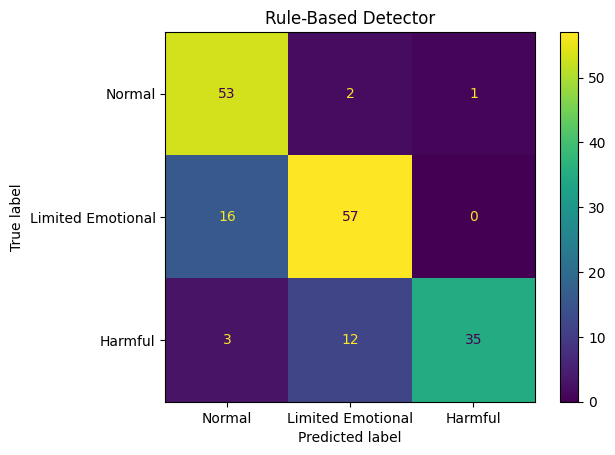

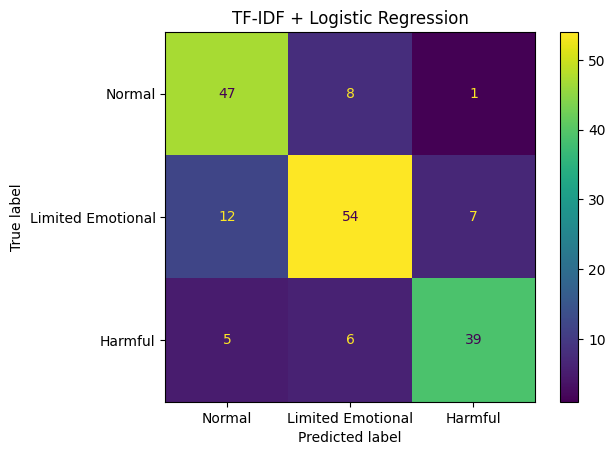

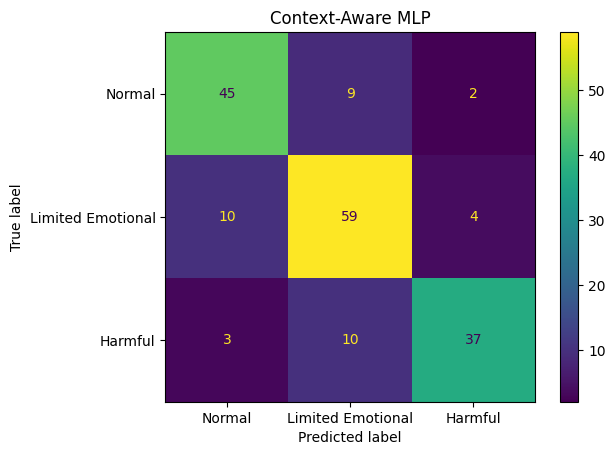

In [16]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

for model_name, predictions in models.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Normal",
            "Limited Emotional",
            "Harmful"
        ]
    )

    disp.plot()

    plt.title(model_name)

    plt.show()

## 15. Save Final Evaluation Results

保存三个模型在最终 test set 上的 Accuracy 和 Macro-F1，供最终报告和结果分析使用。

In [18]:
FINAL_RESULTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_results.csv"
)

final_results_df.to_csv(
    FINAL_RESULTS_PATH,
    index=False
)

print("Saved to:")
print(FINAL_RESULTS_PATH)

display(
    final_results_df.round(4)
)

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\final_test_results.csv


,Model,Accuracy,Macro F1
0,Rule-Based Detector,0.8101,0.8112
1,TF-IDF + Logistic Regression,0.7821,0.7845
2,Context-Aware MLP,0.7877,0.7889


## 16. Save Test Predictions

保存三个模型对每条 test message 的预测结果，用于后续 error analysis。

In [19]:
test_predictions = test_df[
    [
        "annotation_id",
        "match_id",
        "key",
        "label"
    ]
].copy()

test_predictions[
    "rule_prediction"
] = rule_test_predictions

test_predictions[
    "logistic_prediction"
] = logistic_test_predictions

test_predictions[
    "context_prediction"
] = context_test_predictions

TEST_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_predictions.parquet"
)

test_predictions.to_parquet(
    TEST_PREDICTIONS_PATH,
    index=False
)

print("Saved to:")
print(TEST_PREDICTIONS_PATH)

print("\nRows:")
print(len(test_predictions))

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\final_test_predictions.parquet

Rows:
179


## 17. Compare Logistic and Context Errors

比较 Context Model 和 text-only Logistic Regression 的预测结果，查看加入上下文后修正了哪些错误，以及产生了哪些新的错误。

In [20]:
comparison_errors = test_predictions.copy()

comparison_errors[
    "logistic_correct"
] = (
    comparison_errors["logistic_prediction"]
    == comparison_errors["label"]
)

comparison_errors[
    "context_correct"
] = (
    comparison_errors["context_prediction"]
    == comparison_errors["label"]
)

context_fixed = comparison_errors[
    (~comparison_errors["logistic_correct"])
    &
    (comparison_errors["context_correct"])
]

context_hurt = comparison_errors[
    (comparison_errors["logistic_correct"])
    &
    (~comparison_errors["context_correct"])
]

print("Errors fixed by Context:")
print(len(context_fixed))

print("\nCorrect predictions changed to errors:")
print(len(context_hurt))

Errors fixed by Context:
14

Correct predictions changed to errors:
13


In [21]:
display(
    context_fixed[
        [
            "key",
            "label",
            "logistic_prediction",
            "context_prediction"
        ]
    ].head(30)
)

display(
    context_hurt[
        [
            "key",
            "label",
            "logistic_prediction",
            "context_prediction"
        ]
    ].head(30)
)

,key,label,logistic_prediction,context_prediction
556,say the one got fuck by puck,1,2,1
602,commend me for carrying trash blood,2,0,2
637,sorry all guy bad server,1,0,1
772,bg naabs ;),2,0,2
792,or shut the fuck up,2,1,2
830,why wont you rupture me again,1,0,1
850,even me,0,1,0
861,u lil shit,2,1,2
975,cant do shit .,1,2,1
1016,i kill sd,0,1,0


,key,label,logistic_prediction,context_prediction
0,man ur life must be shit,2,2,1
99,fuck yourself,2,2,1
116,AW,0,0,1
251,why are you not ending,1,1,0
378,peace of shit,2,2,1
395,why dont stay?,0,0,1
625,thank wr,0,0,1
626,fuck u jugg,2,2,1
706,are totally shit,2,2,1
832,U CAN HIUT,0,0,2


## 18. Define Ablation Feature Groups

将 Context 分为聊天历史、行为上下文和比赛上下文，用于分析不同类型特征对模型性能的影响。

In [24]:
behaviour_numeric_features = [
    "messages_last_60s",
    "message_interval"
]

behaviour_binary_features = [
    "repeated_message_60s"
]

match_numeric_features = [
    "gold",
    "xp",
    "last_hits",
    "seconds_since_teamfight"
]

match_binary_features = [
    "recent_teamfight_120s",
    "recent_teamfight_loss_120s"
]

print("Behaviour numeric:")
print(behaviour_numeric_features)

print("\nBehaviour binary:")
print(behaviour_binary_features)

print("\nMatch numeric:")
print(match_numeric_features)

print("\nMatch binary:")
print(match_binary_features)

Behaviour numeric:
['messages_last_60s', 'message_interval']

Behaviour binary:
['repeated_message_60s']

Match numeric:
['gold', 'xp', 'last_hits', 'seconds_since_teamfight']

Match binary:
['recent_teamfight_120s', 'recent_teamfight_loss_120s']


### 18.1 Prepare Train and Validation Sets

重新建立 training 和 validation 数据，用于 Ablation Study。

数据仍然使用之前保存的固定 split，不重新划分。

In [26]:
train_df = (
    df[
        df["split"] == "train"
    ]
    .copy()
)

val_df = (
    df[
        df["split"] == "validation"
    ]
    .copy()
)

test_df = (
    df[
        df["split"] == "test"
    ]
    .copy()
)

print("Train:")
print(len(train_df))

print("\nValidation:")
print(len(val_df))

print("\nTest:")
print(len(test_df))

Train:
838

Validation:
183

Test:
179


## 19. Prepare Behaviour Features

处理发言频率、消息间隔和重复消息等行为上下文特征。

In [27]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

behaviour_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_behaviour_numeric = (
    behaviour_imputer.fit_transform(
        train_df[behaviour_numeric_features]
    )
)

X_val_behaviour_numeric = (
    behaviour_imputer.transform(
        val_df[behaviour_numeric_features]
    )
)

X_test_behaviour_numeric = (
    behaviour_imputer.transform(
        test_df[behaviour_numeric_features]
    )
)

behaviour_scaler = StandardScaler()

X_train_behaviour_numeric = (
    behaviour_scaler.fit_transform(
        X_train_behaviour_numeric
    )
)

X_val_behaviour_numeric = (
    behaviour_scaler.transform(
        X_val_behaviour_numeric
    )
)

X_test_behaviour_numeric = (
    behaviour_scaler.transform(
        X_test_behaviour_numeric
    )
)

X_train_behaviour_binary = (
    train_df[behaviour_binary_features]
    .astype(float)
    .to_numpy()
)

X_val_behaviour_binary = (
    val_df[behaviour_binary_features]
    .astype(float)
    .to_numpy()
)

X_test_behaviour_binary = (
    test_df[behaviour_binary_features]
    .astype(float)
    .to_numpy()
)

X_train_behaviour = np.hstack([
    X_train_behaviour_numeric,
    X_train_behaviour_binary
])

X_val_behaviour = np.hstack([
    X_val_behaviour_numeric,
    X_val_behaviour_binary
])

X_test_behaviour = np.hstack([
    X_test_behaviour_numeric,
    X_test_behaviour_binary
])

print("Behaviour feature shape:")
print(X_train_behaviour.shape)

Behaviour feature shape:
(838, 4)


## 20. Prepare Match Features

处理 Gold、XP、Last Hits 和近期团战等比赛上下文特征，并使用 training set 完成缺失值处理和标准化。

In [28]:
match_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_match_numeric = (
    match_imputer.fit_transform(
        train_df[match_numeric_features]
    )
)

X_val_match_numeric = (
    match_imputer.transform(
        val_df[match_numeric_features]
    )
)

X_test_match_numeric = (
    match_imputer.transform(
        test_df[match_numeric_features]
    )
)

match_scaler = StandardScaler()

X_train_match_numeric = (
    match_scaler.fit_transform(
        X_train_match_numeric
    )
)

X_val_match_numeric = (
    match_scaler.transform(
        X_val_match_numeric
    )
)

X_test_match_numeric = (
    match_scaler.transform(
        X_test_match_numeric
    )
)

X_train_match_binary = (
    train_df[match_binary_features]
    .astype(float)
    .to_numpy()
)

X_val_match_binary = (
    val_df[match_binary_features]
    .astype(float)
    .to_numpy()
)

X_test_match_binary = (
    test_df[match_binary_features]
    .astype(float)
    .to_numpy()
)

X_train_match = np.hstack([
    X_train_match_numeric,
    X_train_match_binary
])

X_val_match = np.hstack([
    X_val_match_numeric,
    X_val_match_binary
])

X_test_match = np.hstack([
    X_test_match_numeric,
    X_test_match_binary
])

print("Match feature shape:")
print(X_train_match.shape)

Match feature shape:
(838, 7)


## 21. Rebuild Text Features for Ablation

使用已经训练并保存的 TF-IDF 和 SVD 组件转换 training、validation 和 test 文本。

这里只使用 transform，不重新训练文本处理组件。

In [29]:
for data in [
    train_df,
    val_df,
    test_df
]:
    data["current_text"] = (
        data["key"]
        .fillna("")
        .astype(str)
    )

    data["history_text"] = (
        data[history_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
        .str.strip()
    )

In [30]:
X_train_current = current_svd.transform(
    current_tfidf.transform(
        train_df["current_text"]
    )
)

X_val_current = current_svd.transform(
    current_tfidf.transform(
        val_df["current_text"]
    )
)

X_test_current = current_svd.transform(
    current_tfidf.transform(
        test_df["current_text"]
    )
)


X_train_history = history_svd.transform(
    history_tfidf.transform(
        train_df["history_text"]
    )
)

X_val_history = history_svd.transform(
    history_tfidf.transform(
        val_df["history_text"]
    )
)

X_test_history = history_svd.transform(
    history_tfidf.transform(
        test_df["history_text"]
    )
)

print("Current text:")
print(
    X_train_current.shape,
    X_val_current.shape,
    X_test_current.shape
)

print("\nHistory text:")
print(
    X_train_history.shape,
    X_val_history.shape,
    X_test_history.shape
)

Current text:
(838, 50) (183, 50) (179, 50)

History text:
(838, 50) (183, 50) (179, 50)


## 22. Prepare Ablation Labels

准备 training、validation 和 test 的标签，供 Ablation Study 使用。

In [31]:
y_train = (
    train_df["label"]
    .astype(int)
    .to_numpy()
)

y_val = (
    val_df["label"]
    .astype(int)
    .to_numpy()
)

y_test = (
    test_df["label"]
    .astype(int)
    .to_numpy()
)

print("Train labels:")
print(y_train.shape)

print("\nValidation labels:")
print(y_val.shape)

print("\nTest labels:")
print(y_test.shape)

Train labels:
(838,)

Validation labels:
(183,)

Test labels:
(179,)


## 23. Build Ablation Configurations

逐步加入聊天历史、行为上下文和比赛上下文，建立四组 Ablation 输入特征。

In [33]:
ablation_features = {
    "Current Text": (
        X_train_current,
        X_val_current,
        X_test_current
    ),

    "Current + History": (
        np.hstack([
            X_train_current,
            X_train_history
        ]),
        np.hstack([
            X_val_current,
            X_val_history
        ]),
        np.hstack([
            X_test_current,
            X_test_history
        ])
    ),

    "Current + History + Behaviour": (
        np.hstack([
            X_train_current,
            X_train_history,
            X_train_behaviour
        ]),
        np.hstack([
            X_val_current,
            X_val_history,
            X_val_behaviour
        ]),
        np.hstack([
            X_test_current,
            X_test_history,
            X_test_behaviour
        ])
    ),

    "Full Context": (
        np.hstack([
            X_train_current,
            X_train_history,
            X_train_behaviour,
            X_train_match
        ]),
        np.hstack([
            X_val_current,
            X_val_history,
            X_val_behaviour,
            X_val_match
        ]),
        np.hstack([
            X_test_current,
            X_test_history,
            X_test_behaviour,
            X_test_match
        ])
    )
}

for name, (
    X_train_ab,
    X_val_ab,
    X_test_ab
) in ablation_features.items():

    print(
        name,
        X_train_ab.shape,
        X_val_ab.shape,
        X_test_ab.shape
    )

Current Text (838, 50) (183, 50) (179, 50)
Current + History (838, 100) (183, 100) (179, 100)
Current + History + Behaviour (838, 104) (183, 104) (179, 104)
Full Context (838, 111) (183, 111) (179, 111)


## 24. Define Ablation Training Function

使用相同的 MLP 结构和训练参数训练每组 Ablation 模型。

最佳 epoch 只根据 validation Macro-F1 选择，test set 不参与模型选择。

In [36]:
import copy
import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

from sklearn.metrics import f1_score


class AblationMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)

In [37]:
def train_ablation_model(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    epochs=50
):

    torch.manual_seed(339)
    np.random.seed(339)

    model = AblationMLP(
        X_train.shape[1]
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_dataset = TensorDataset(
        torch.tensor(
            X_train,
            dtype=torch.float32
        ),
        torch.tensor(
            y_train,
            dtype=torch.long
        )
    )

    generator = torch.Generator()
    generator.manual_seed(339)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    X_val_tensor = torch.tensor(
        X_val,
        dtype=torch.float32
    ).to(device)

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).to(device)

    best_val_f1 = 0
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        model.train()

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            loss.backward()
            optimizer.step()

        model.eval()

        with torch.no_grad():

            val_predictions = (
                torch.argmax(
                    model(X_val_tensor),
                    dim=1
                )
                .cpu()
                .numpy()
            )

        val_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro"
        )

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(
        best_state
    )

    model.eval()

    with torch.no_grad():

        test_predictions = (
            torch.argmax(
                model(X_test_tensor),
                dim=1
            )
            .cpu()
            .numpy()
        )

    test_f1 = f1_score(
        y_test,
        test_predictions,
        average="macro"
    )

    return {
        "best_epoch": best_epoch,
        "validation_macro_f1": best_val_f1,
        "test_macro_f1": test_f1
    }

## 25. Run Ablation Study

依次训练四种特征组合，并记录最佳 validation Macro-F1 和最终 test Macro-F1。

In [38]:
ablation_results = []

for name, (
    X_train_ab,
    X_val_ab,
    X_test_ab
) in ablation_features.items():

    print("Training:", name)

    result = train_ablation_model(
        X_train_ab,
        X_val_ab,
        X_test_ab,
        y_train,
        y_val,
        y_test
    )

    ablation_results.append({
        "Configuration": name,
        "Input Dimensions": X_train_ab.shape[1],
        "Best Epoch": result["best_epoch"],
        "Validation Macro F1":
            result["validation_macro_f1"],
        "Test Macro F1":
            result["test_macro_f1"]
    })

    print(
        "Validation Macro-F1:",
        round(
            result["validation_macro_f1"],
            4
        )
    )

    print(
        "Test Macro-F1:",
        round(
            result["test_macro_f1"],
            4
        )
    )

    print()

Training: Current Text
Validation Macro-F1: 0.8416
Test Macro-F1: 0.8224

Training: Current + History
Validation Macro-F1: 0.8434
Test Macro-F1: 0.8117

Training: Current + History + Behaviour
Validation Macro-F1: 0.811
Test Macro-F1: 0.7894

Training: Full Context
Validation Macro-F1: 0.8089
Test Macro-F1: 0.7758



## 26. Show Ablation Results

汇总不同上下文特征组合的实验结果，分析聊天历史、行为特征和比赛状态分别带来的影响。

In [39]:
ablation_results_df = pd.DataFrame(
    ablation_results
)

display(
    ablation_results_df.round(4)
)

,Configuration,Input Dimensions,Best Epoch,Validation Macro F1,Test Macro F1
0,Current Text,50,46,0.8416,0.8224
1,Current + History,100,49,0.8434,0.8117
2,Current + History + Behaviour,104,20,0.8110,0.7894
3,Full Context,111,25,0.8089,0.7758


## 27. Show Complete Ablation Results

完整显示 Ablation Study 的 validation 和 test Macro-F1，比较不同上下文特征组合的效果。

In [40]:
print(
    ablation_results_df[
        [
            "Configuration",
            "Input Dimensions",
            "Best Epoch",
            "Validation Macro F1",
            "Test Macro F1"
        ]
    ].to_string(index=False)
)

                Configuration  Input Dimensions  Best Epoch  Validation Macro F1  Test Macro F1
                 Current Text                50          46             0.841631       0.822370
            Current + History               100          49             0.843390       0.811696
Current + History + Behaviour               104          20             0.811046       0.789409
                 Full Context               111          25             0.808946       0.775805


## 28. Save Ablation Results

保存 Ablation Study 结果，供最终报告和实验分析使用。

In [41]:
ABLATION_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ablation_results.csv"
)

ablation_results_df.to_csv(
    ABLATION_PATH,
    index=False
)

print("Saved to:")
print(ABLATION_PATH)

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\ablation_results.csv


## 29. Print Final Ablation Results

完整显示 Ablation Study 的结果，方便后续报告中比较不同上下文特征的贡献。

In [42]:
print(
    ablation_results_df[
        [
            "Configuration",
            "Input Dimensions",
            "Best Epoch",
            "Validation Macro F1",
            "Test Macro F1"
        ]
    ].round(4).to_string(index=False)
)

                Configuration  Input Dimensions  Best Epoch  Validation Macro F1  Test Macro F1
                 Current Text                50          46               0.8416         0.8224
            Current + History               100          49               0.8434         0.8117
Current + History + Behaviour               104          20               0.8110         0.7894
                 Full Context               111          25               0.8089         0.7758


## 30. Final Output Check

检查最终实验结果文件是否已经成功生成。

In [43]:
output_files = [
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_results.csv",

    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_predictions.parquet",

    PROJECT_ROOT
    / "data"
    / "processed"
    / "ablation_results.csv"
]

for path in output_files:
    print(
        path.name,
        "->",
        path.exists()
    )

final_test_results.csv -> True
final_test_predictions.parquet -> True
ablation_results.csv -> True
